#Imports

In [1]:
!pip install qiskit
!pip install qiskit_aer
!pip install qiskit_ibm_runtime
!pip install pylatexenc
!pip install networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 51.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 92.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.5/49.5 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.0/109.0 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 102.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 30.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.9/363.9 kB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.8/64.8 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.5/130.5 kB 13.8 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.3
    Uninstalling requests-2.32.3:
      Successfully uninstalled requests-2.32.3
ERROR: pip's dependency resolver does not current

In [215]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh, FakeSherbrooke
from qiskit.transpiler import generate_preset_pass_manager, CouplingMap, TranspileLayout
from qiskit.visualization import plot_circuit_layout

from math import pi


#E-bit Pairs

In [ ]:
#q1 -> ctrl; q2 -> com1; q3 -> com2;
def cat_entangler() -> QuantumCircuit:
  qReg = QuantumRegister(3)
  cl_reg = ClassicalRegister(1, name='ClComm')
  cat_qc = QuantumCircuit(qReg,cl_reg)
  cat_qc.h(1)
  cat_qc.cx(1,2)

  cat_qc.cx(0,1)
  cat_qc.measure(1,0)
  with cat_qc.if_test((0,1)):
    cat_qc.x(1)
    cat_qc.x(2)

  return cat_qc

ent_qc = cat_entangler()
ent_qc.draw('mpl')

In [ ]:
#q1 -> ctrl; q2 -> com2;
def cat_disentangler() -> QuantumCircuit:
  qReg = QuantumRegister(2)
  cl_reg = ClassicalRegister(1, name='ClComm')
  uncat_qc = QuantumCircuit(qReg,cl_reg)
  uncat_qc.h(1)
  uncat_qc.measure(1,0)
  with uncat_qc.if_test((0,1)):
    uncat_qc.z(0)
    uncat_qc.x(1)

  return uncat_qc

dis_qc = cat_disentangler()
dis_qc.draw('mpl')

In [ ]:
#Example usage of e-bit pairs
# Create Quantum Registers
control = QuantumRegister(1, name='Control')
comm = QuantumRegister(2, name='Comm')
target = QuantumRegister(1, name='Target')

# Create Classical Register
creg = ClassicalRegister(1, name='ClComm')

# Create Quantum Circuit
qc = QuantumCircuit(control, comm, target, creg)
qc_cat = cat_entangler()


qc = qc.compose(qc_cat, range(3), clbits=[creg[0]])
qc.cx(2,3)
qc = qc.compose(cat_disentangler(), [control[0],comm[1]], clbits=creg[0])


qc.draw('mpl')

#Distributed QFT (Vernec, 2025)

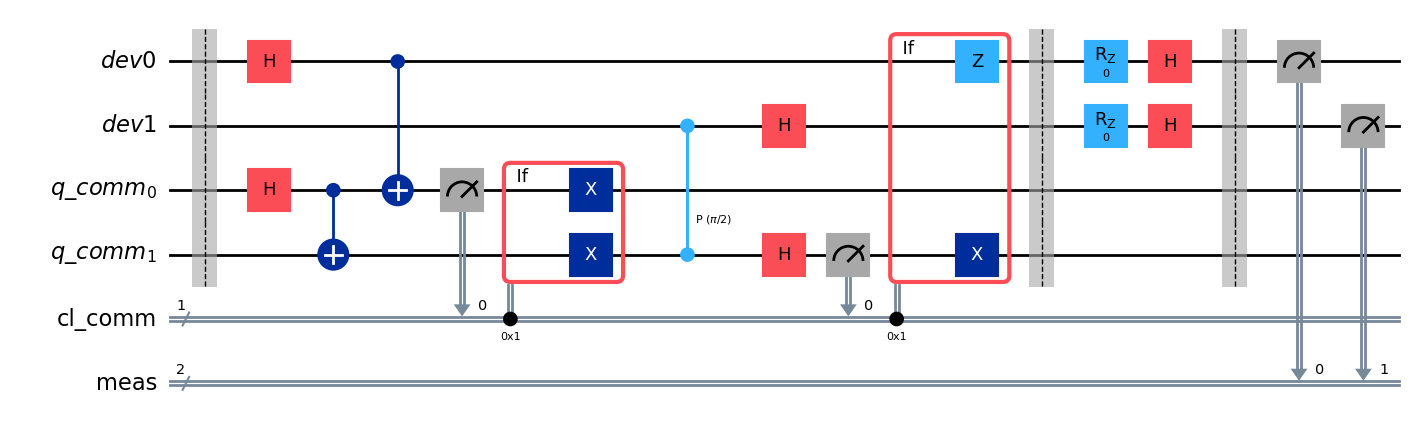

In [355]:
#assumes one communicative qubit per device, uniform device size
def qft_circuit_dist(n_qubits: int, n_devices : int, device_size : int) -> QuantumCircuit:
  if n_qubits > n_devices*device_size:
    print('not enough device space')
    return

  c = ClassicalRegister(1, 'cl_comm')
  qc = QuantumCircuit(c)


  #qubit allocation
  full_devices = min(n_qubits // device_size, n_devices)
  remainder = n_qubits % device_size

  for i in range(full_devices):
    qc.add_register(QuantumRegister(device_size, f'dev{i}'))

  if full_devices < n_devices and remainder > 0:
    qc.add_register(QuantumRegister(remainder, f'dev{full_devices}'))

  qc.add_register(QuantumRegister(n_devices, 'q_comm'))



  #circuit logic

  #loops through devices
  for dev_idx, qreg in enumerate(qc.qregs[:-1]):

    # print(f"QuantumRegister: {qreg.name}")

    for i, idx_qubit in enumerate(qreg):
      angleCoeff = 1
      # print(f"  Current qubit: {idx_qubit}")
      qc.h(idx_qubit)
      for next_qubit in qreg[i+1:]:
        # print(f"    Later qubit in same device: {next_qubit}")
        qc.cp(pi/(2**angleCoeff), idx_qubit, next_qubit)
        angleCoeff += 1


      #looping subsequent devices
      for later_dev_idx, later_dev in enumerate(qc.qregs[dev_idx + 1:-1], dev_idx+1):
        # qc.barrier()
        #cat entangler
        qc.h(qc.qregs[-1][dev_idx])
        qc.cx(qc.qregs[-1][dev_idx], qc.qregs[-1][later_dev_idx])

        qc.cx(idx_qubit, qc.qregs[-1][dev_idx])
        qc.measure(qc.qregs[-1][dev_idx], c)
        with qc.if_test((c,1)):
          qc.x(qc.qregs[-1][dev_idx])
          qc.x(qc.qregs[-1][later_dev_idx])


        for other_qubit in later_dev:
          # print(f"    Qubit from subsequent device {later_dev.name}: {other_qubit}")
          qc.cp(pi/(2**angleCoeff), qc.qregs[-1][later_dev_idx], other_qubit)
          angleCoeff += 1


        #cat disentangler
        qc.h(qc.qregs[-1][later_dev_idx])
        qc.measure(qc.qregs[-1][later_dev_idx], c)
        with qc.if_test((c,1)):
          qc.z(idx_qubit)
          qc.x(qc.qregs[-1][later_dev_idx])

        # qc.barrier()

  return qc

n_qubits = 2
qcs = []
for x in range(2**n_qubits):
    c = ClassicalRegister(1, 'cl_comm')
    qc = QuantumCircuit(c)
    qc.add_register(QuantumRegister(1, 'dev0'))
    qc.add_register(QuantumRegister(1, 'dev1'))
    qc.add_register(QuantumRegister(2, 'q_comm'))
    qc.add_register(ClassicalRegister(n_qubits, 'meas'))

    x_bits = [int(bit_str) for bit_str in f"{x:0>{n_qubits}b}"]
    for i,x_bit in enumerate(x_bits):
        if x_bit == 1:
          qc.x(i)
    qc.barrier()
    qc = qc.compose(qft_circuit_dist(n_qubits,2,1),qubits=range(n_qubits+2))
    qc.barrier()

    for i,j in zip(range(n_qubits), range(n_qubits-1,-1,-1)):
        angle = pi * x / 2**j
        qc.rz(-angle, i)
        qc.h(i)

    qc.barrier()

    # qc.save_statevector()

    for i in range(n_qubits):
      qc.measure(i,i+1)

    qcs.append(qc)


qcs[0].draw('mpl')


##Single QPU Backend Configuration

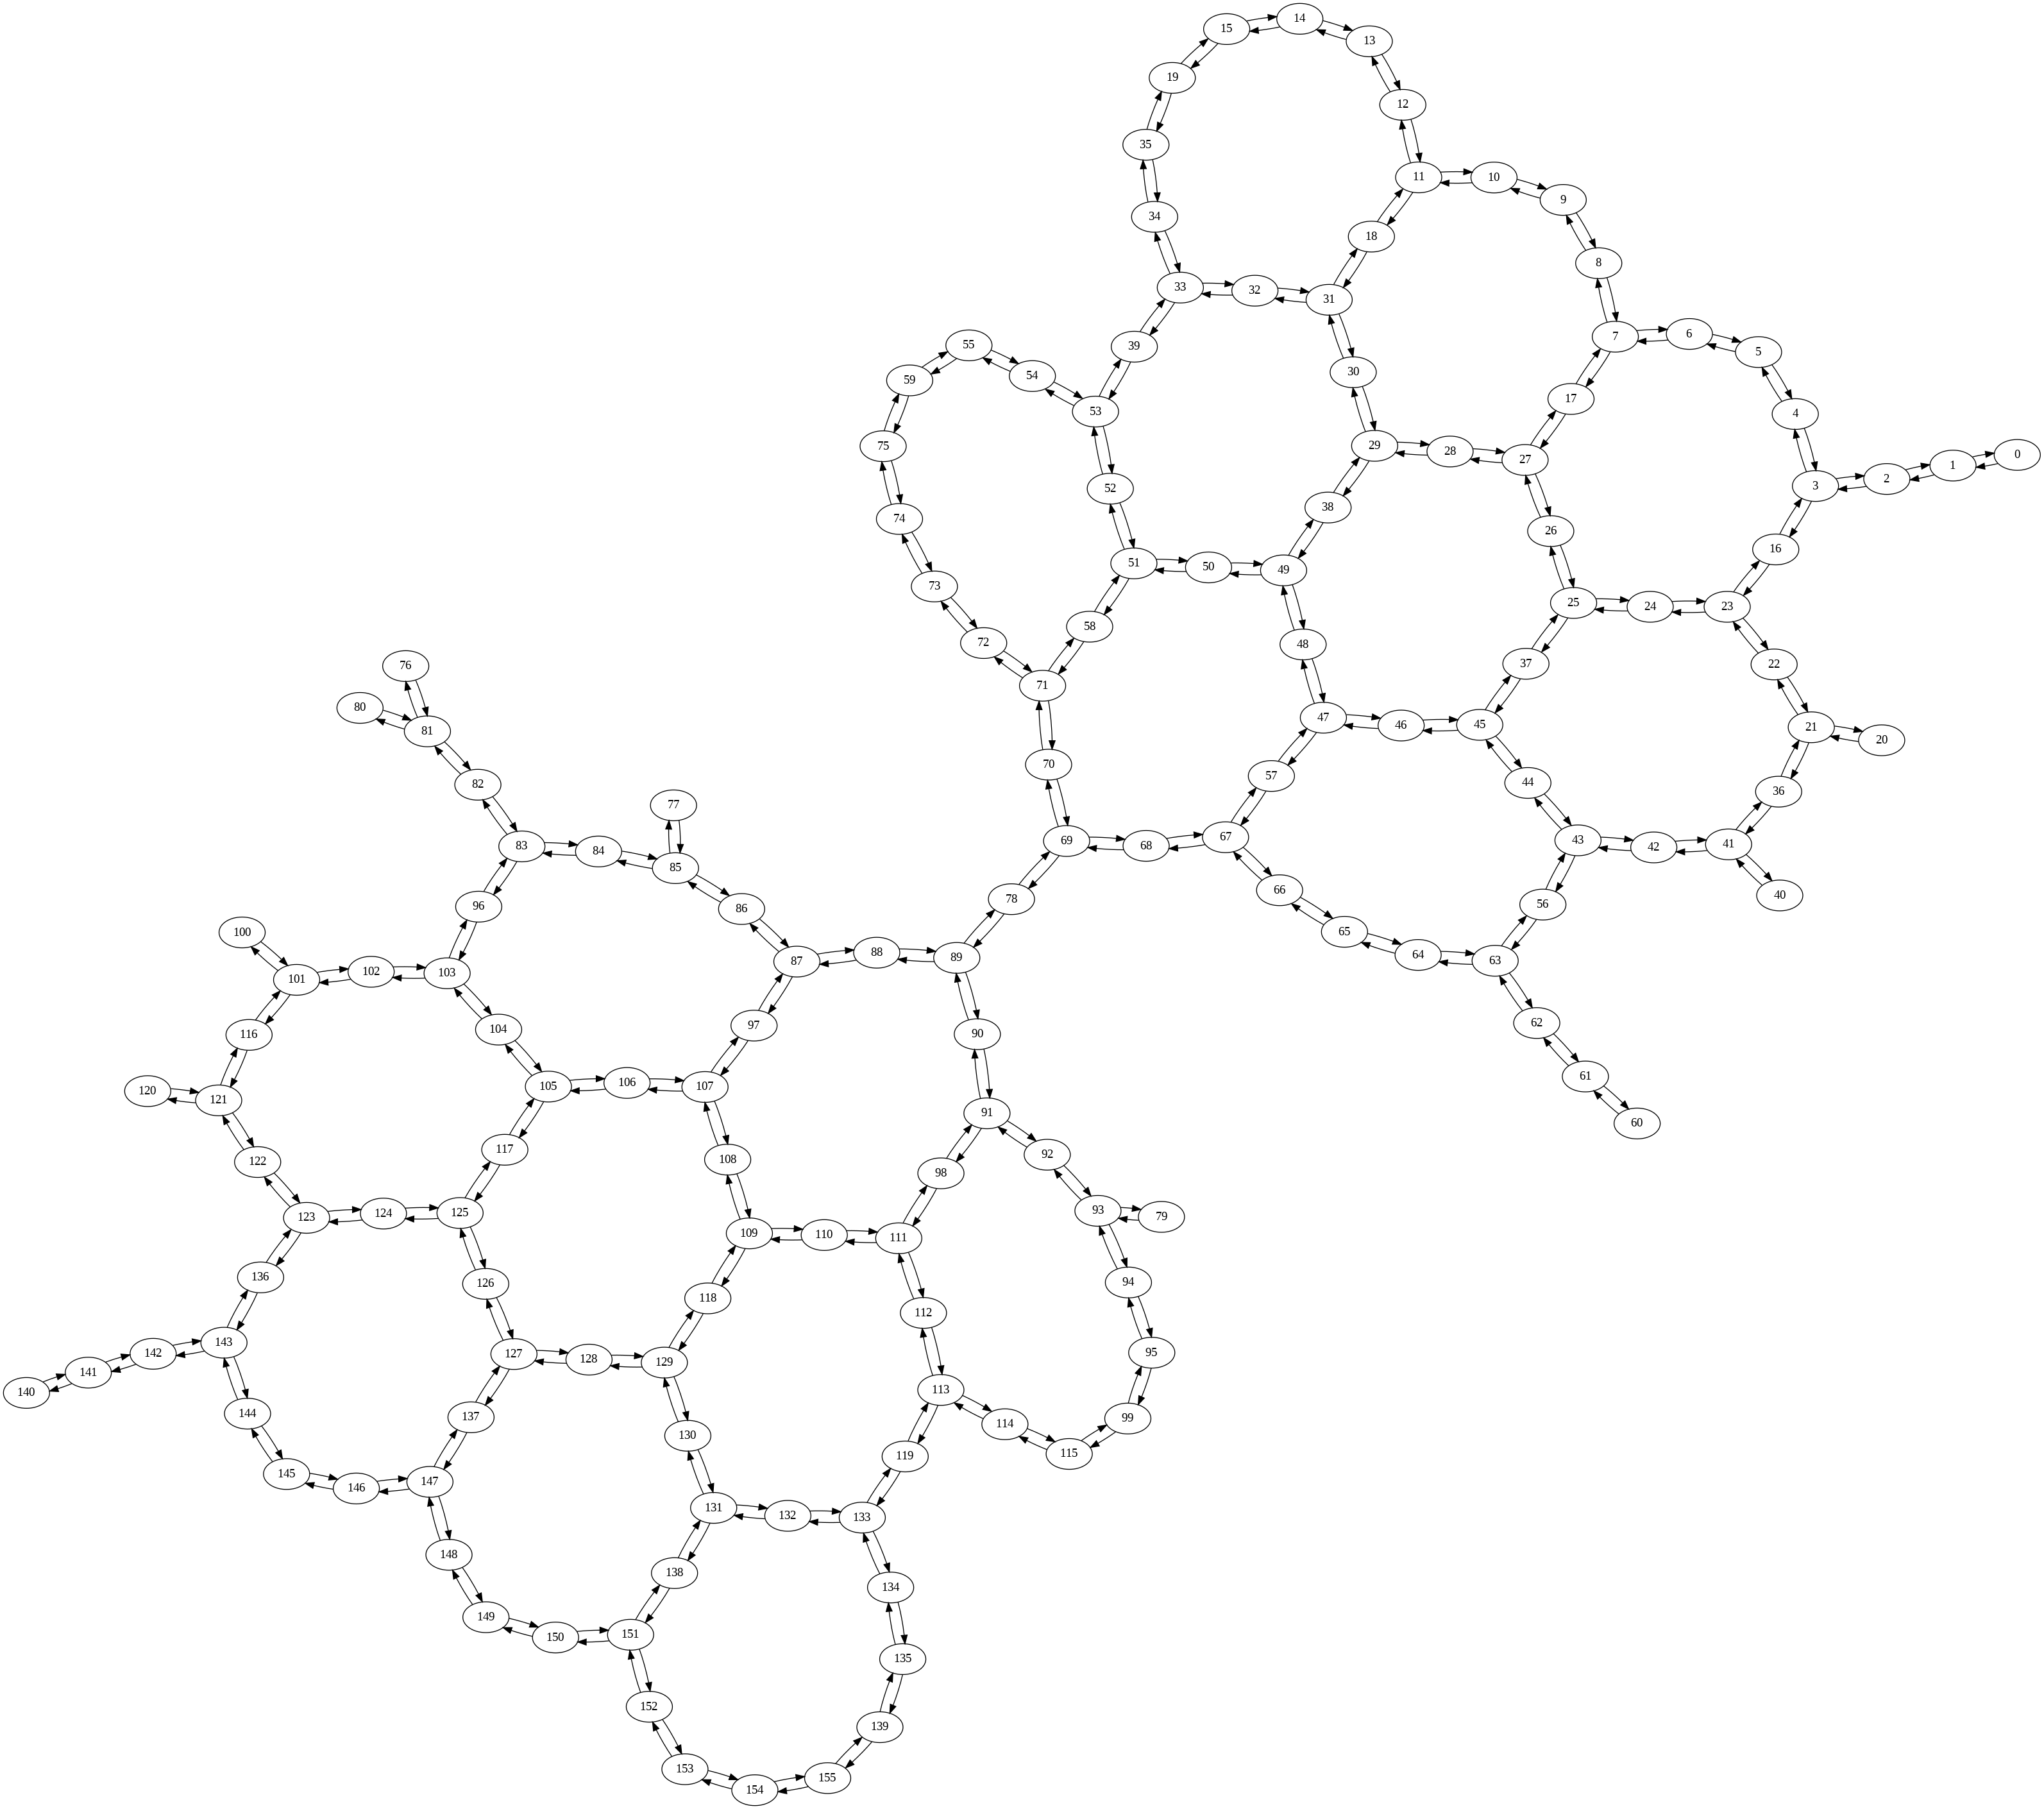

In [158]:
backend = FakeMarrakesh()
original_map_list = backend.configuration().coupling_map
original_map = CouplingMap(couplinglist=original_map_list)
cloned_map = CouplingMap(couplinglist=original_map_list)

#https://quantum.ibm.com/services/resources?resourceType=current-instance&system=ibm_marrakesh
dev_a = {61, 65, 73}
dev_b = {76, 77, 79}

for u, v in list(cloned_map.get_edges()):
  if (u in dev_a and v in dev_b) or (u in dev_b and v in dev_a):
    cloned_map.graph.remove_edge(u, v)



# q_comm_reg = next(reg for reg in dist_qft.qregs if reg.name == 'q-comm')
# comm_layout = {
#   q_comm_reg[0]: 69,
#   q_comm_reg[1]: 78
# }


# original_map.draw()
cloned_map.draw()

##Transpilation

In [57]:
backend = FakeMarrakesh()

In [ ]:
# from qiskit.transpiler import Layout
# from qiskit.transpiler.coupling import CouplingMap


# def complete_layout_by_register(partial_layout_dict, circuit, backend, register_ranges):
#     """
#     Complete a layout by assigning remaining logical qubits to physical qubits
#     based on register grouping and physical qubit ranges.

#     Args:
#         partial_layout_dict (dict): {Qubit: physical_index}
#         circuit (QuantumCircuit)
#         backend (Backend)
#         register_ranges (dict): {register_name: (start_idx, end_idx)} inclusive
#     """
#     num_physical = backend.configuration().num_qubits
#     coupling_map = CouplingMap(backend.configuration().coupling_map)

#     full_layout = Layout()
#     used_physical = set()

#     # Add fixed mappings
#     for logical_q, physical_q in partial_layout_dict.items():
#         full_layout[logical_q] = physical_q
#         used_physical.add(physical_q)

#     # Group remaining logical qubits by register
#     register_qubits = {}
#     for q in circuit.qubits:
#         if q not in full_layout:
#             reg_name = q._register.name
#             print(reg_name)
#             register_qubits.setdefault(reg_name, []).append(q)

#     # Assign qubits per register
#     for reg_name, logical_qubits in register_qubits.items():
#         if reg_name not in register_physical_map:
#             raise ValueError(f"No physical qubit set specified for register '{reg_name}'")

#         allowed_physical = [q for q in register_physical_map[reg_name] if q not in used_physical]

#         # Rank by connectivity
#         connectivity = {q: len(coupling_map.neighbors(q)) for q in allowed_physical}
#         sorted_physical = sorted(allowed_physical, key=lambda q: connectivity[q], reverse=True)

#         if len(logical_qubits) > len(sorted_physical):
#             raise ValueError(f"Not enough physical qubits for register '{reg_name}'")

#         for logical_q, physical_q in zip(logical_qubits, sorted_physical):
#             full_layout[logical_q] = physical_q
#             used_physical.add(physical_q)

#     return full_layout


# q_comm_register = next(reg for reg in dist_qft.qregs if reg.name == "q-comm")
# q_comm_qubits = q_comm_register[:]

# layout_dict = {q_comm_qubits[0]: 78, q_comm_qubits[1]: 89}

# register_physical_map = {
#     "dev0": set(range(0, 75)),
#     "q-comm": {78, 89},
#     "dev1": set([76, 77] + list(range(79, 89)) + list(range(90, 156)))
# }


# dist_qft_initial_layout = complete_layout_by_register(layout_dict, dist_qft, backend=backend, register_ranges=register_physical_map)

/tmp/ipython-input-357-1007033382.py:80: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  pm = generate_preset_pass_manager(


dingdong
dingdong
dingdong
dingdong
dingdong
dingdong
dingdong
dingdong
dingdong
dingdong
dingdong
dingdong
dingdong
dingdong
dingdong
dingdong
dingdong
dingdong
dingdong
dingdong


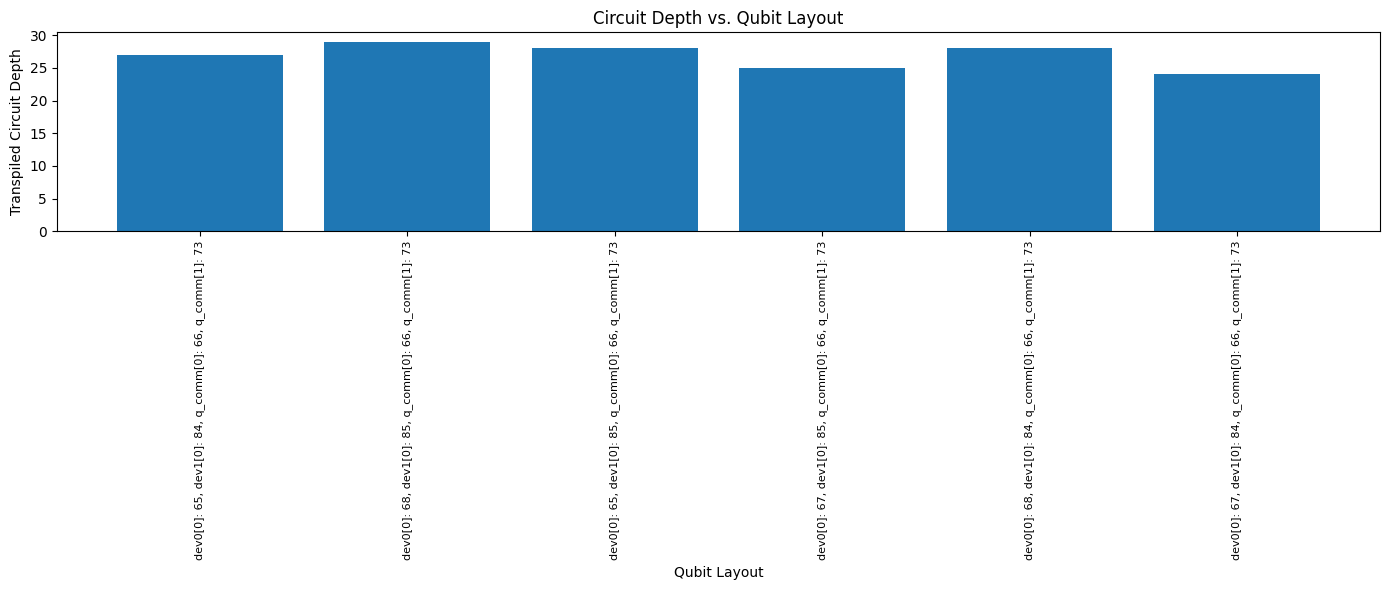

In [357]:
import random
import matplotlib.pyplot as plt
from qiskit.transpiler import Layout
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

dist_qft = qft_circuit_dist(2,2,1)


def get_qubits_by_register_name(circuit, register_name):
    for reg in circuit.qregs:
        if reg.name == register_name:
            return reg[:]
    raise ValueError(f"Register '{register_name}' not found.")

def generate_random_layout(dist_qft, q_comm_layout, register_physical_map, seed=None):
    if seed is not None: random.seed(seed)
    layout = Layout()
    used_physical = set(q_comm_layout.values())

    # Add fixed q-comm layout
    for q, p in q_comm_layout.items():
        layout[q] = p

    # Randomly assign dev0 and dev1
    for reg_name in ["dev0", "dev1"]:
        logical_qubits = get_qubits_by_register_name(dist_qft, reg_name)
        physical_pool = list(register_physical_map[reg_name] - used_physical)
        if len(logical_qubits) > len(physical_pool):
            raise ValueError(f"Not enough physical qubits for {reg_name}")
        random.shuffle(physical_pool)
        for q, p in zip(logical_qubits, physical_pool):
            layout[q] = p
            used_physical.add(p)

    return layout

def layout_to_str(layout, circuit):
    layout_strs = []
    for q in circuit.qubits:
        reg_name = get_register_name(circuit, q)
        reg_idx = get_register_index(circuit, q)
        phys = layout[q]
        layout_strs.append(f"{reg_name}[{reg_idx}]: {phys}")
    return ", ".join(sorted(layout_strs))

def get_register_name(circuit, qubit):
    _, reg_info = circuit.find_bit(qubit)
    return reg_info[0][0].name if reg_info else None

def get_register_index(circuit, qubit):
    _, reg_info = circuit.find_bit(qubit)
    return reg_info[0][1] if reg_info else None

def run_random_layout_experiments(dist_qft, backend, cloned_map, num_trials=20):
    # q_comm_register = next(reg for reg in dist_qft.qregs if reg.name == "q-comm")
    # q_comm_qubits = q_comm_register[:]
    # q_comm_layout = {q_comm_qubits[0]: 78, q_comm_qubits[1]: 89}

    # register_physical_map = {
    #     "dev0": set(range(67, 71)),
    #     "q-comm": {78, 89},
    #     "dev1": set([87, 88, 90, 91])
    # }
    q_comm_register = next(reg for reg in dist_qft.qregs if reg.name == "q_comm")
    q_comm_qubits = q_comm_register[:]
    q_comm_layout = {q_comm_qubits[0]: 66, q_comm_qubits[1]: 73}

    register_physical_map = {
        "dev0": set([67,68,65]),
        "q_comm": {66, 73},
        "dev1": set([84,85])
    }

    results = {}

    for i in range(num_trials):
        layout = generate_random_layout(dist_qft, q_comm_layout, register_physical_map, 123456789+i)
        layout_key = layout_to_str(layout, dist_qft)

        pm = generate_preset_pass_manager(
            optimization_level=3,
            backend=backend,
            coupling_map=cloned_map,
            initial_layout=layout,
            seed_transpiler=123456789
        )
        tdist_qft = pm.run(dist_qft)
        depth = tdist_qft.depth()
        if depth < 100:
          tdist_qft_final = layout
          print('dingdong')
        results[layout_key] = depth

    return results, tdist_qft_final

def plot_layout_depth_histogram(results):
    plt.figure(figsize=(14, 6))
    labels = list(results.keys())
    depths = list(results.values())

    # Create vertical bar chart
    plt.bar(range(len(labels)), depths, tick_label=range(len(labels)))
    plt.xticks(range(len(labels)), labels, rotation=90, fontsize=8)
    plt.ylabel("Transpiled Circuit Depth")
    plt.xlabel("Qubit Layout")
    plt.title("Circuit Depth vs. Qubit Layout")
    plt.tight_layout()
    plt.show()


results, tdist_qft_final_layout = run_random_layout_experiments(dist_qft, backend, cloned_map, num_trials=20)
plot_layout_depth_histogram(results)

## Manual Transpilation

In [ ]:
# import networkx as nx
# from qiskit.converters import circuit_to_dag
# from qiskit.transpiler import Layout
# from qiskit.transpiler.coupling import CouplingMap
# from networkx.algorithms.community import greedy_modularity_communities

# def get_register_name(circuit, qubit):
#     _, reg_info = circuit.find_bit(qubit)
#     return reg_info[0][0].name if reg_info else None

# def build_interaction_graph(circuit):
#     dag = circuit_to_dag(circuit)
#     G = nx.Graph()
#     for node in dag.two_qubit_ops():
#         q0, q1 = node.qargs
#         if G.has_edge(q0, q1):
#             G[q0][q1]['weight'] += 1
#         else:
#             G.add_edge(q0, q1, weight=1)
#     return G

# def complete_layout_with_clustering(partial_layout_dict, circuit, backend, register_physical_map):
#     coupling_map = CouplingMap(backend.configuration().coupling_map)
#     full_layout = Layout()
#     used_physical = set()

#     # Add fixed mappings
#     for logical_q, physical_q in partial_layout_dict.items():
#         full_layout[logical_q] = physical_q
#         used_physical.add(physical_q)

#     # Build interaction graph
#     interaction_graph = build_interaction_graph(circuit)

#     # Group remaining logical qubits by register
#     register_qubits = {}
#     for q in circuit.qubits:
#         if q not in full_layout:
#             reg_name = get_register_name(circuit, q)
#             register_qubits.setdefault(reg_name, []).append(q)

#     # Assign clusters per register
#     for reg_name, logical_qubits in register_qubits.items():
#         if reg_name not in register_physical_map:
#             raise ValueError(f"No physical qubit set specified for register '{reg_name}'")

#         allowed_physical = [q for q in register_physical_map[reg_name] if q not in used_physical]
#         connectivity = {q: len(coupling_map.neighbors(q)) for q in allowed_physical}
#         sorted_physical = sorted(allowed_physical, key=lambda q: connectivity[q], reverse=True)

#         if len(logical_qubits) > len(sorted_physical):
#             raise ValueError(f"Not enough physical qubits for register '{reg_name}'")

#         # Cluster logical qubits by interaction
#         subgraph = interaction_graph.subgraph(logical_qubits)
#         clusters = list(greedy_modularity_communities(subgraph))

#         # Assign each cluster to a chunk of physical qubits
#         physical_idx = 0
#         for cluster in clusters:
#             cluster = list(cluster)
#             cluster_size = len(cluster)
#             cluster_phys = sorted_physical[physical_idx:physical_idx + cluster_size]
#             if len(cluster_phys) < cluster_size:
#                 raise ValueError(f"Not enough physical qubits for cluster in register '{reg_name}'")
#             for logical_q, physical_q in zip(cluster, cluster_phys):
#                 full_layout[logical_q] = physical_q
#                 used_physical.add(physical_q)
#             physical_idx += cluster_size

#     return full_layout

# q_comm_register = next(reg for reg in dist_qft.qregs if reg.name == "q-comm")
# q_comm_qubits = q_comm_register[:]

# layout_dict = {q_comm_qubits[0]: 78, q_comm_qubits[1]: 89}

# register_physical_map = {
#     "dev0": set(range(0, 76)),
#     "q-comm": {78, 89},
#     "dev1": set([76, 77] + list(range(79, 89)) + list(range(90, 156)))
# }


# dist_qft_initial_layout = complete_layout_with_clustering(layout_dict, dist_qft, backend=backend, register_physical_map=register_physical_map)

In [59]:
pm = generate_preset_pass_manager(optimization_level = 3, backend = backend, coupling_map=cloned_map, initial_layout='INSERT HERE')

/tmp/ipython-input-59-9501670.py:1: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  pm = generate_preset_pass_manager(optimization_level = 3, backend = backend, coupling_map=cloned_map)


In [76]:
tdist_qft = pm.run(dist_qft)


q_comm_reg = None
dev1_reg = None
dev0_reg = None
for reg in tdist_qft.layout.initial_layout.get_registers():
  if reg.name == 'q-comm':
    q_comm_reg = reg
  if reg.name == 'dev0':
    dev0_reg = reg
  if reg.name == 'dev1':
    dev1_reg = reg



for indx, vqubit in tdist_qft.layout.initial_layout.get_virtual_bits().items():
  if indx in q_comm_reg:
    print('qubit',vqubit,'indx',  indx)
  if indx in dev0_reg:
    print('dev0 qubit',vqubit,'indx',  indx)


print(dist_qft.depth())
print(tdist_qft.depth())
# tdist_qft.draw('mpl', scale=0.4, fold=200)

qubit 93 indx <Qubit register=(2, "q-comm"), index=1>
qubit 94 indx <Qubit register=(2, "q-comm"), index=0>
dev0 qubit 95 indx <Qubit register=(2, "dev0"), index=0>
dev0 qubit 99 indx <Qubit register=(2, "dev0"), index=1>
19
78


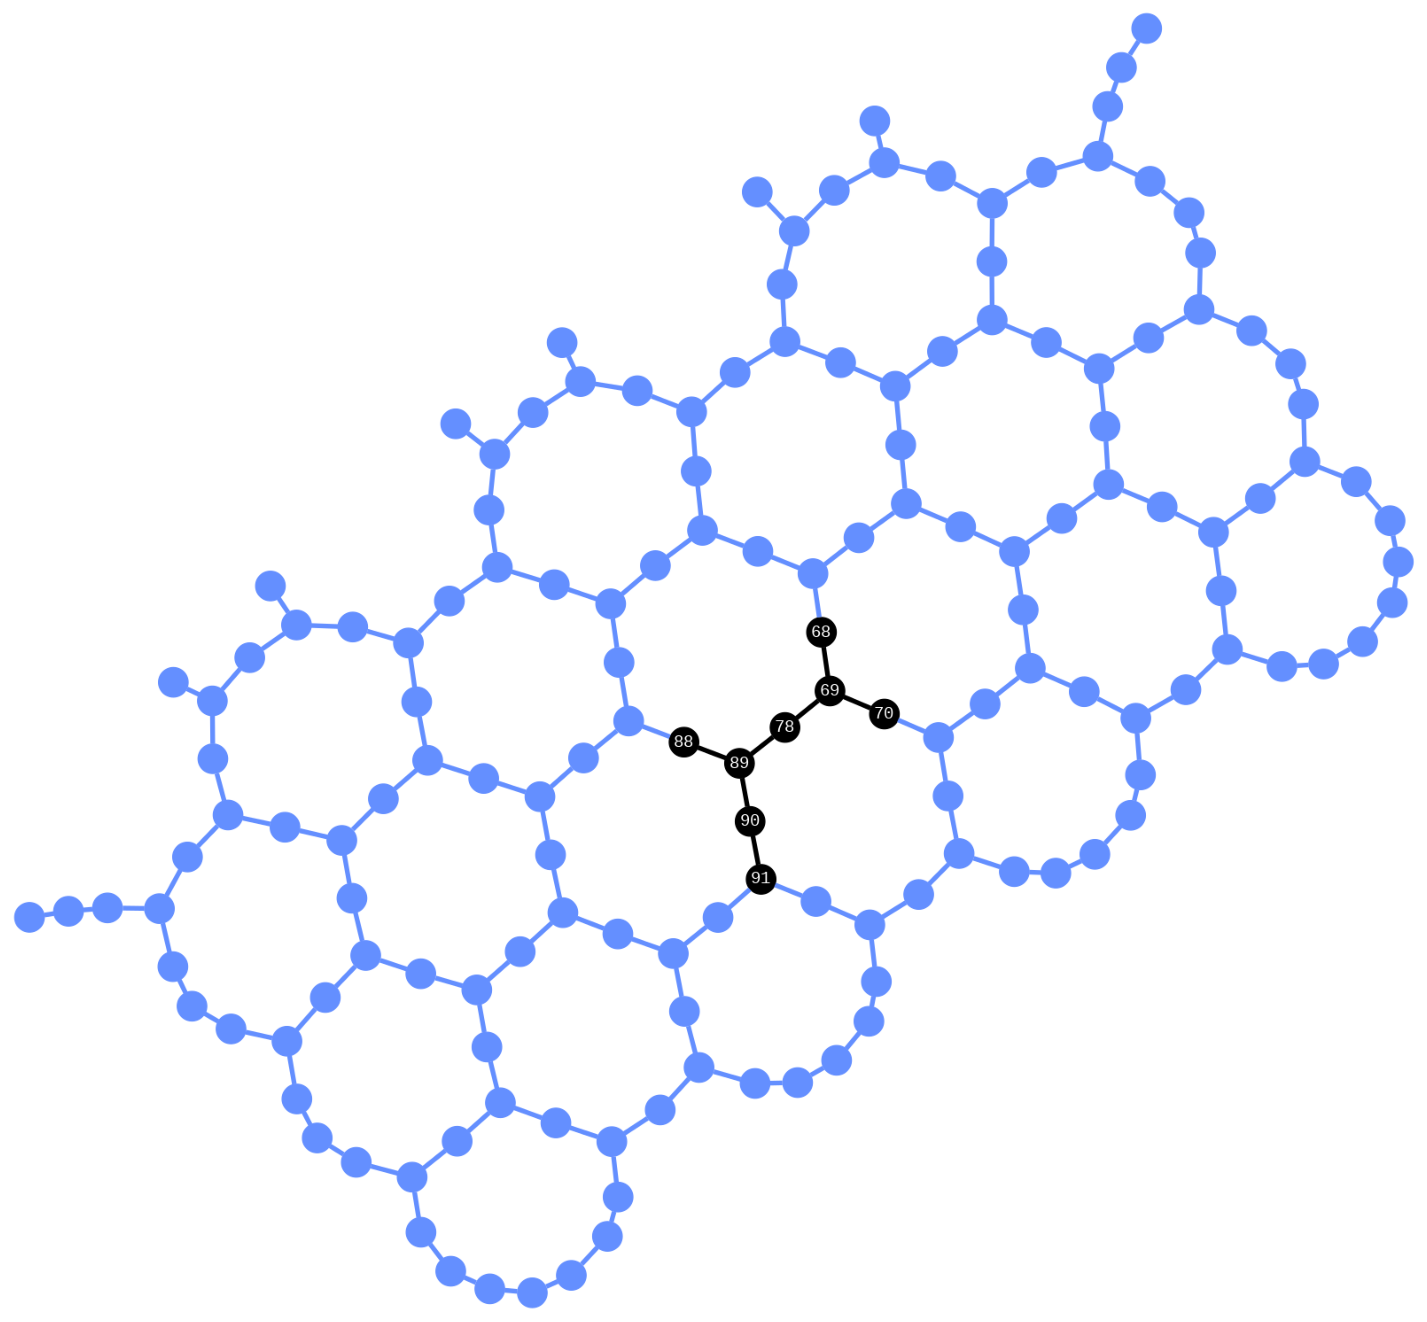

In [127]:
plot_circuit_layout(tdist_qft_final, backend, view="physical")
# tdist_qft_layout.set_size_inches(8,8)

# Using Eagle Processor

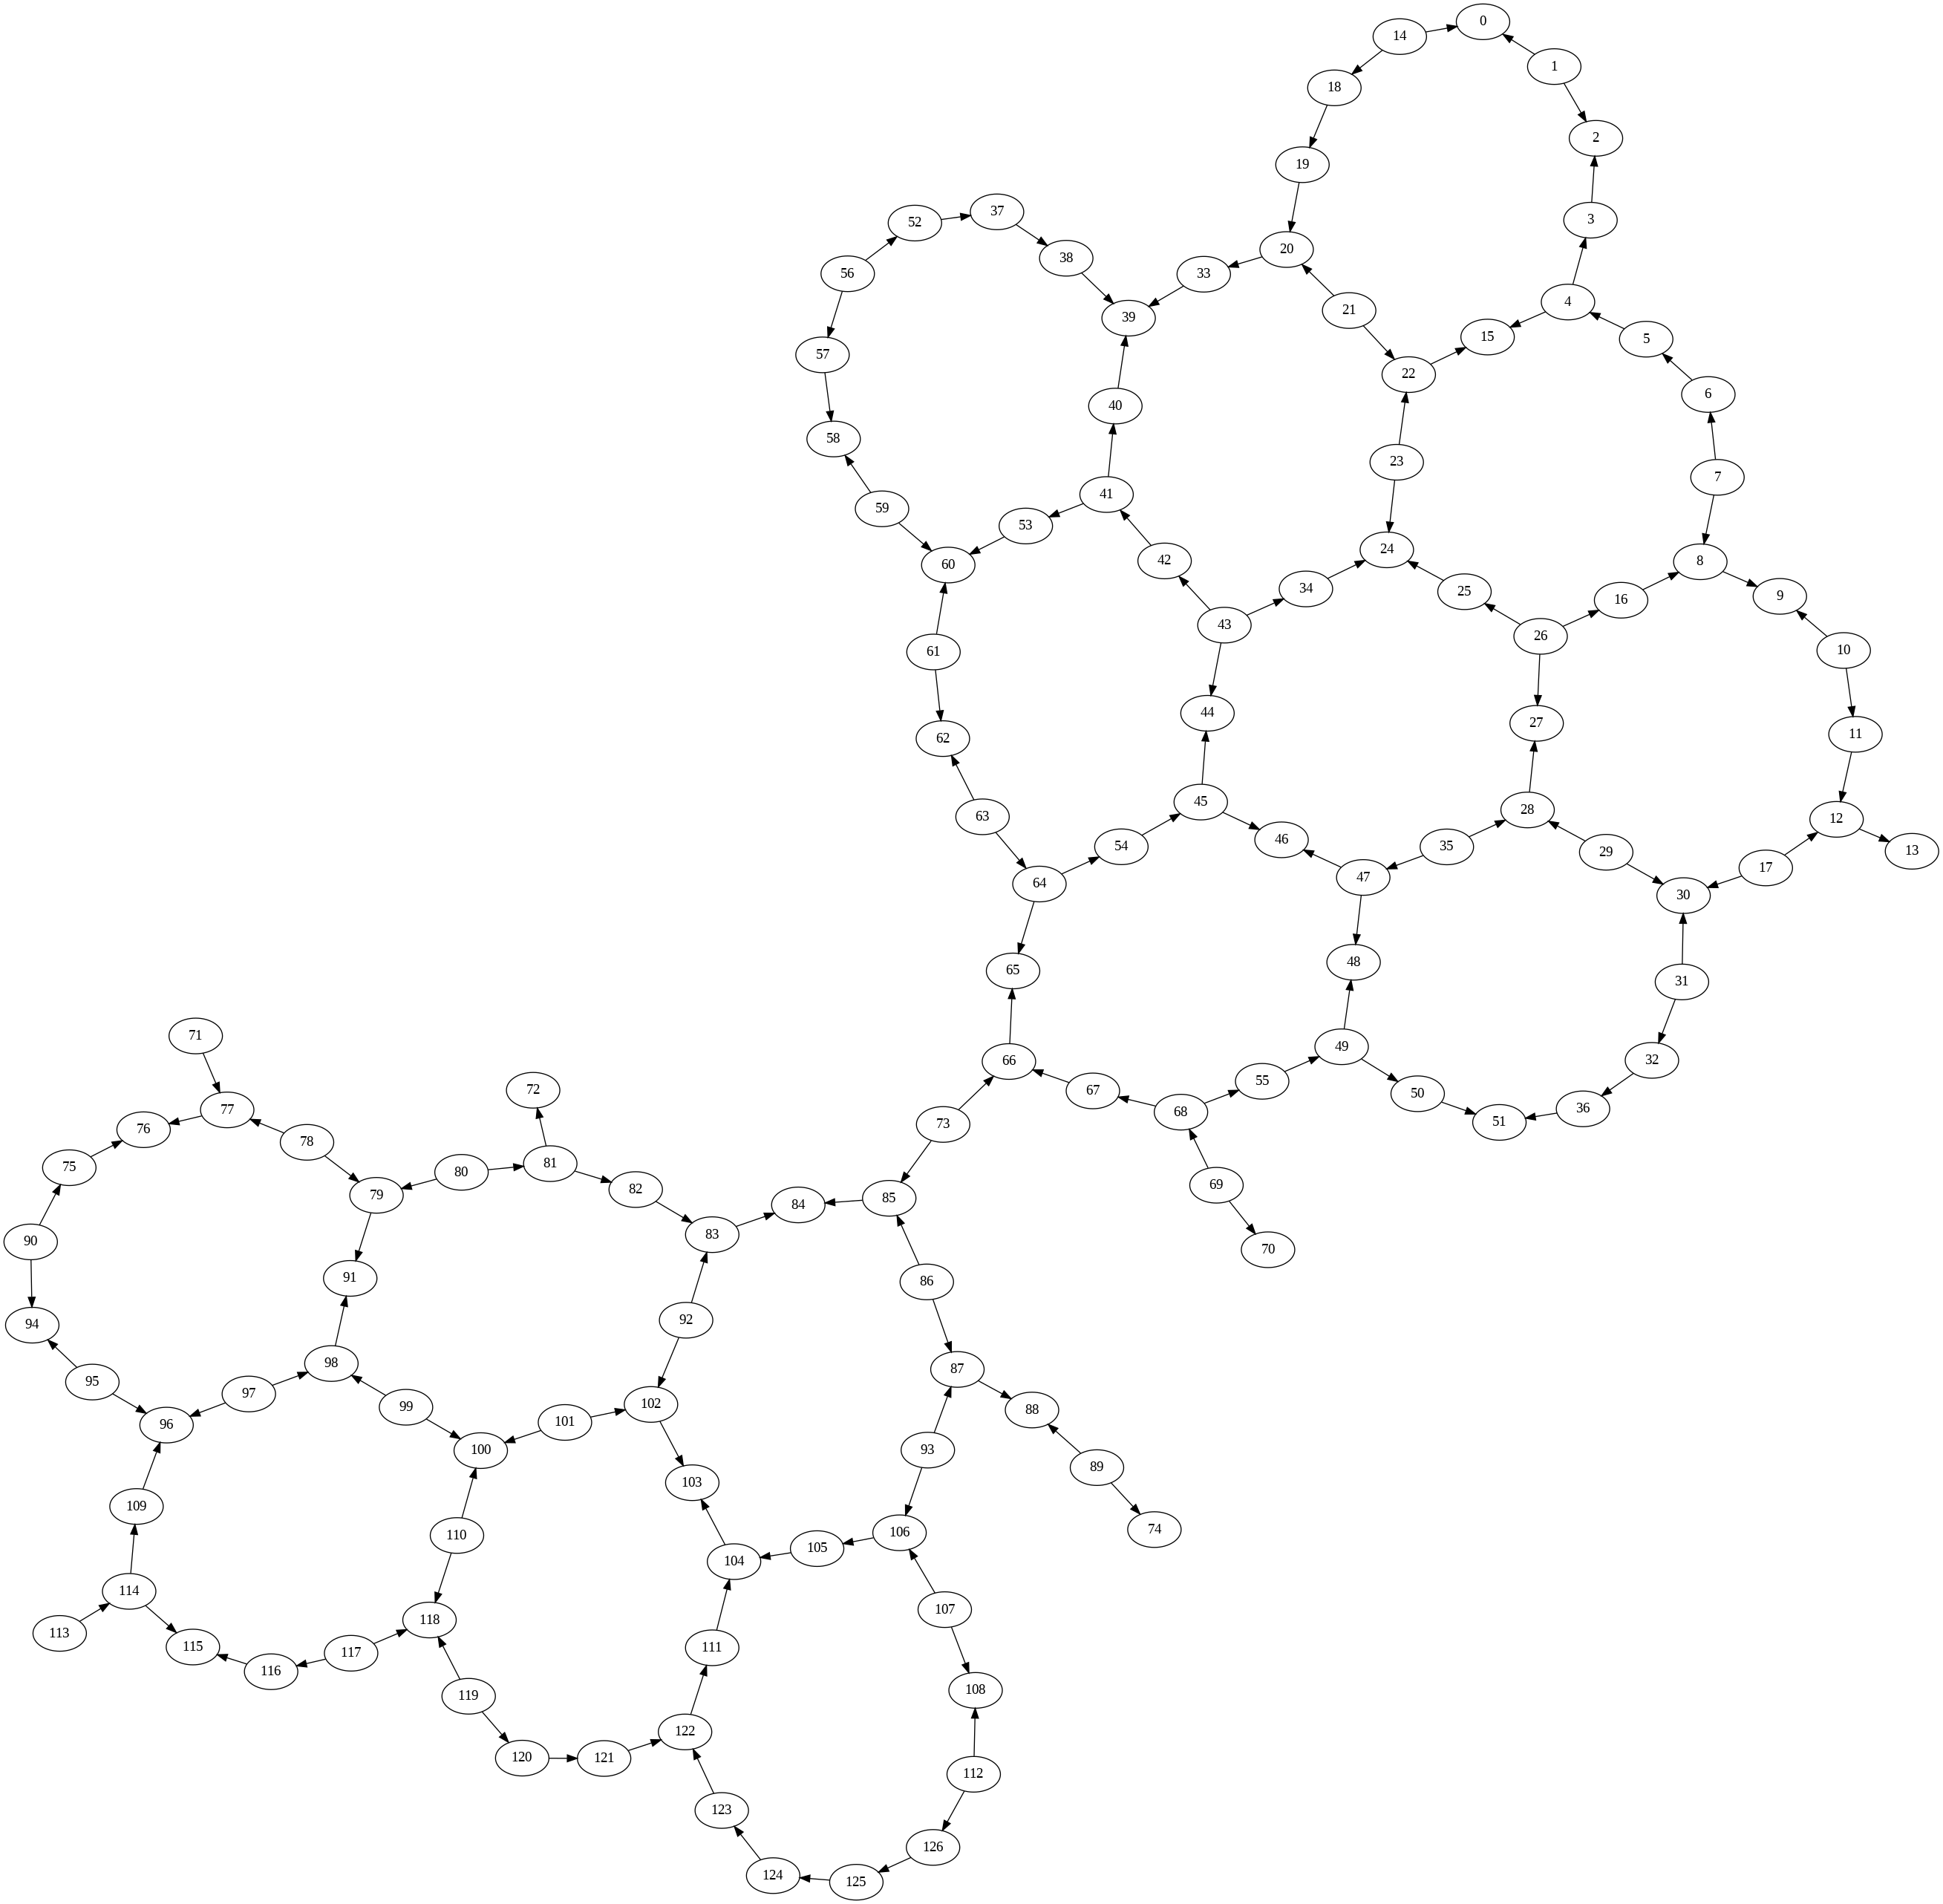

In [232]:
backend = FakeSherbrooke()
original_map_list = backend.configuration().coupling_map
original_map = CouplingMap(couplinglist=original_map_list)
cloned_map = CouplingMap(couplinglist=original_map_list)

#https://quantum.ibm.com/services/resources?resourceType=current-instance&system=ibm_marrakesh
dev_a = {58, 62, 70}
dev_b = {71, 72, 74}

for u, v in list(cloned_map.get_edges()):
  if (u in dev_a and v in dev_b) or (u in dev_b and v in dev_a):
    cloned_map.graph.remove_edge(u, v)



# q_comm_reg = next(reg for reg in dist_qft.qregs if reg.name == 'q-comm')
# comm_layout = {
#   q_comm_reg[0]: 69,
#   q_comm_reg[1]: 78
# }


# original_map.draw()
cloned_map.draw()

/tmp/ipython-input-204-1919110553.py:78: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  pm = generate_preset_pass_manager(


dingdong
dingdong


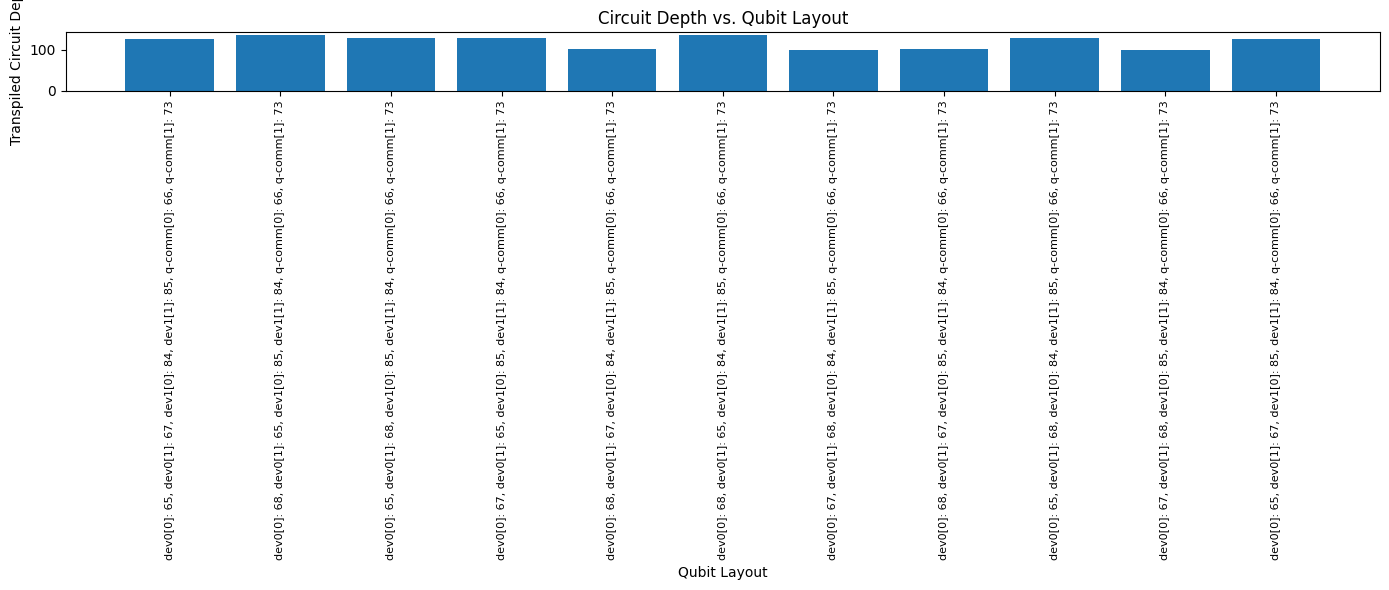

In [209]:
results, tdist_qft_final = run_random_layout_experiments(dist_qft, backend, cloned_map, num_trials=20)
plot_layout_depth_histogram(results)

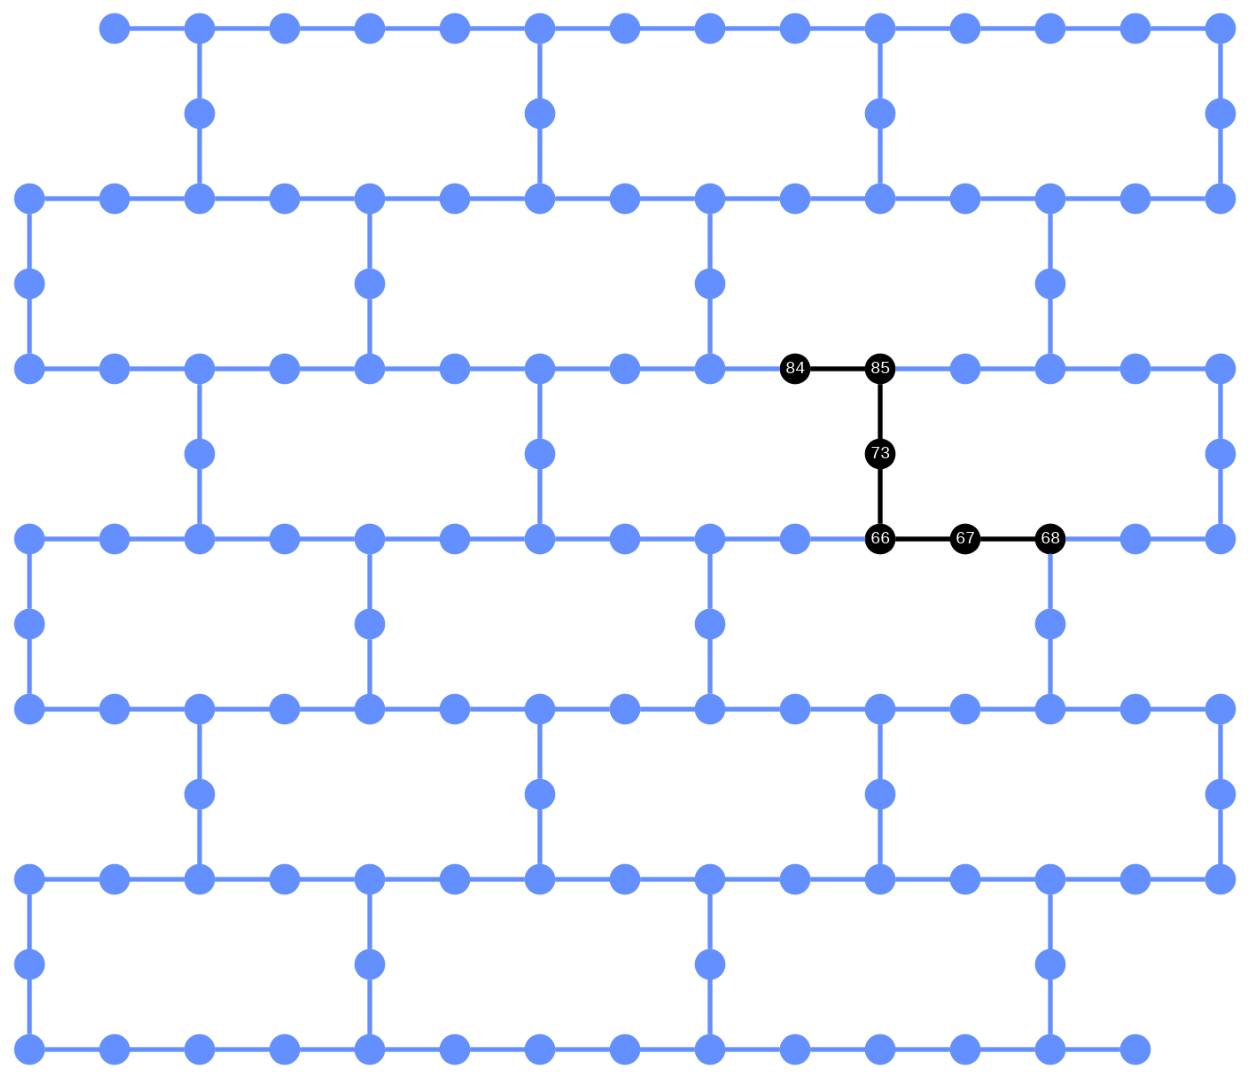

In [214]:
plot_circuit_layout(tdist_qft_final, backend, view='physical')

# Fidelities

Layout({
66: <Qubit register=(2, "q_comm"), index=0>,
73: <Qubit register=(2, "q_comm"), index=1>,
65: <Qubit register=(1, "dev0"), index=0>,
85: <Qubit register=(1, "dev1"), index=0>
})
[<Qubit register=(1, "dev0"), index=0>, <Qubit register=(1, "dev1"), index=0>, <Qubit register=(2, "q_comm"), index=0>, <Qubit register=(2, "q_comm"), index=1>]


/tmp/ipython-input-358-3538285409.py:4: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  pm_final = generate_preset_pass_manager(optimization_level=3, backend=backend, coupling_map=cloned_map,initial_layout=tdist_qft_final_layout)


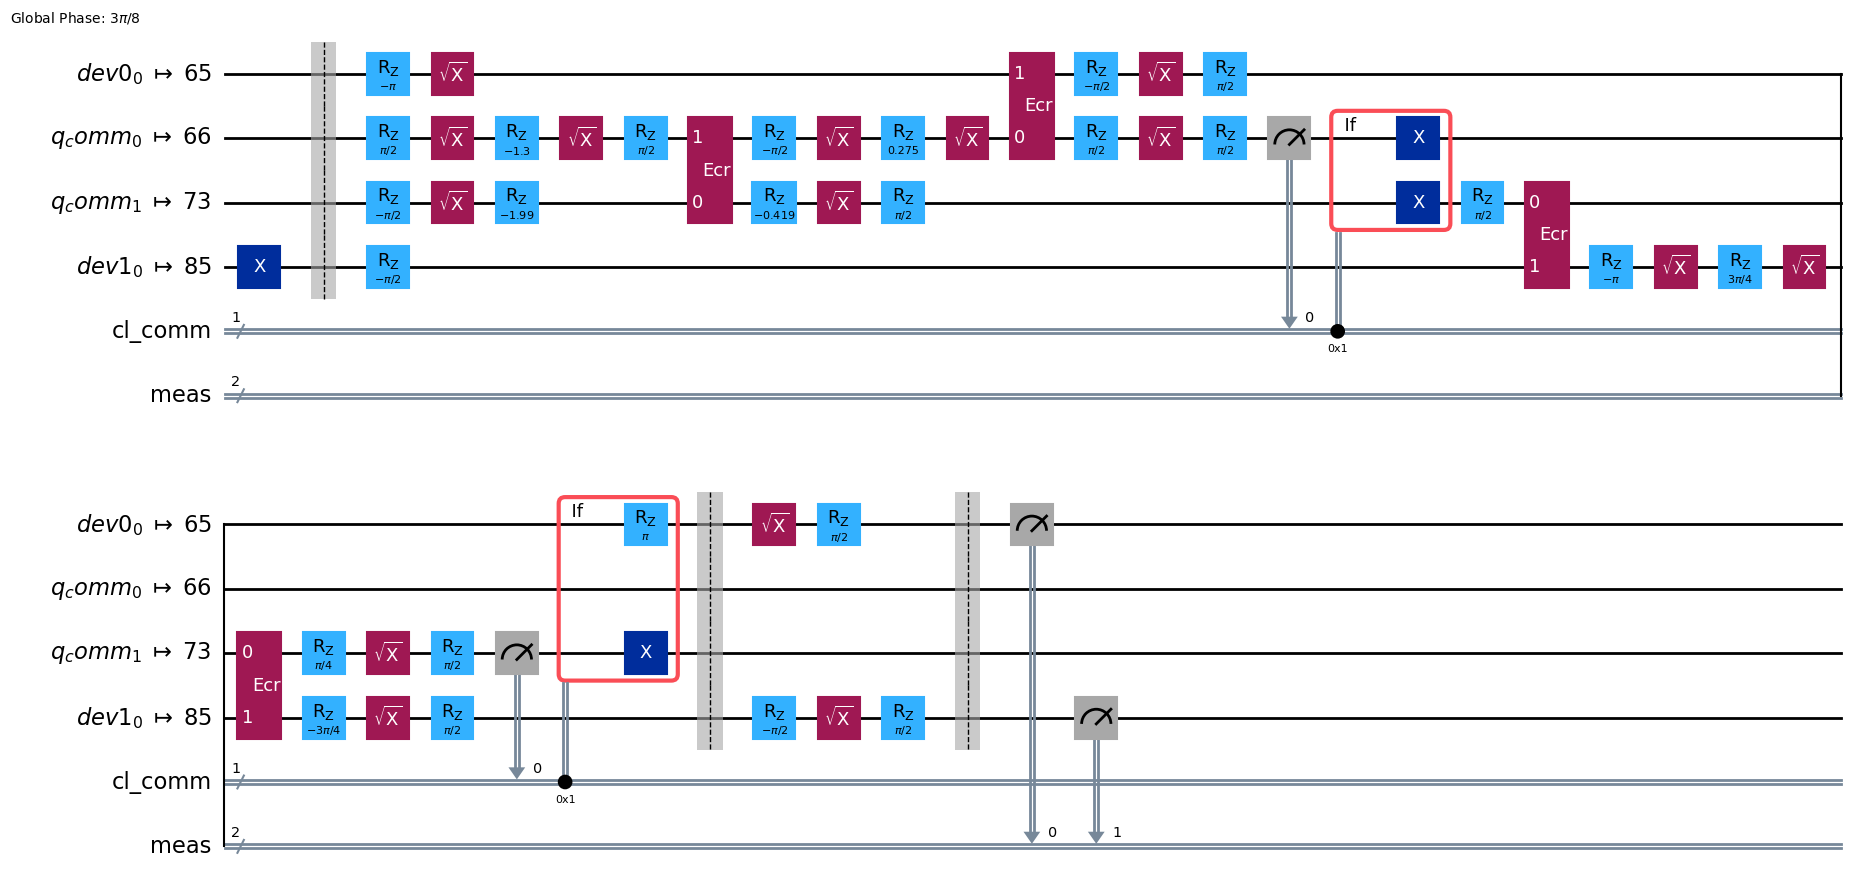

In [358]:
backend = FakeSherbrooke()
print(tdist_qft_final_layout)
print(qcs[0].qubits)
pm_final = generate_preset_pass_manager(optimization_level=3, backend=backend, coupling_map=cloned_map,initial_layout=tdist_qft_final_layout)
isa_qcs = [pm_final.run(qc) for qc in qcs]

isa_qc = isa_qcs[1]
isa_qc.draw('mpl')

In [362]:
mappings = [isa_qc.layout.input_qubit_mapping for isa_qc in isa_qcs]
for mapping1, mapping2 in zip(mappings, mappings[1:]):
    assert mapping1 == mapping2

In [363]:
from qiskit_ibm_runtime import (
    QiskitRuntimeService,
    Batch,
    SamplerV2 as Sampler,
)

In [364]:
with Batch(backend=backend):
    sampler = Sampler()
    job = sampler.run(isa_qcs)
results = job.result()

In [365]:
num_shots = results[0].data.meas.num_shots
counts = [result.data.meas.get_counts() for result in results]
print(counts)
fidelities = [count['0'*n_qubits]/num_shots*100 for count in counts]
for fidelity in fidelities:
    print(f"{fidelity=:.2f}%")

[{'00': 853, '10': 111, '11': 12, '01': 48}, {'00': 797, '10': 145, '01': 71, '11': 11}, {'00': 849, '10': 105, '01': 63, '11': 7}, {'00': 808, '10': 120, '01': 78, '11': 18}]
fidelity=83.30%
fidelity=77.83%
fidelity=82.91%
fidelity=78.91%


In [359]:
from qiskit_aer import AerSimulator
simulator_aer = AerSimulator()



In [360]:
result = simulator_aer.run(circuits=isa_qc, shots = 1000, method='statevector').result()
counts = result.get_counts()
print(counts)

{'00 1': 523, '00 0': 477}


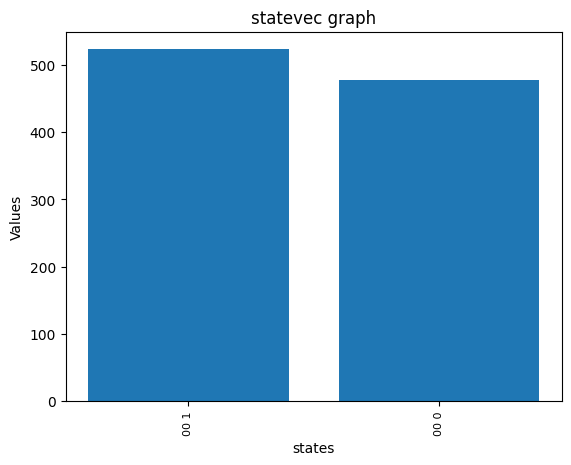

<Figure size 2000x600 with 0 Axes>

In [361]:
categories = list(counts.keys())
values = list(counts.values())

plt.bar(categories, values)
plt.xlabel('states')
plt.xticks(range(len(categories)), categories, rotation=90, fontsize=8)
plt.ylabel('Values')
plt.title('statevec graph')
plt.figure(figsize=[20,6])
plt.show()